# Example: KMT-2025-BLG-1616 — a planet whose degeneracy only the DREAMS data break

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published planetary events, and compare the maps with the published ones.

**The event.** KMT-2025-BLG-1616 (Yang, Zang et al. 2026, *KMT-2025-BLG-1616Lb: First Microlensing Bound Planet From
DREAMS*, arXiv:2601.11469) is a short (*t*ₑ ≈ 8 d) high-magnification event on a faint source (*I*_S ≈ 22) that peaked
on HJD′ ≈ 10857.76. It lies in the overlap of two KMTNet fields (BLG01 and BLG42, four points per hour together),
and was also observed by PRIME (*H* band) and by the DREAMS survey with DECam (*z* and *r*, 20 points per hour at the
peak). The paper finds four solutions with *q* ≈ 4.8 × 10⁻⁴: close/wide pairs of a central and a resonant caustic.
With all data, the resonant pair is preferred by Δχ² ≈ 330 because only it reproduces the U-shaped anomaly seen by
DECam. **Without the DREAMS data the four solutions are within Δχ² = 0.5** (their Table 3, KMTNet and PRIME).

**Their map.** As for KMT-2025-BLG-0811 (same group and method): a coarse grid of 61 × 61 points over
−1.5 ≤ log *s* ≤ 1.5, −6 ≤ log *q* ≤ 0, then a dense grid of 201 × 31 points over −0.2 ≤ log *s* ≤ 0.2,
−4.5 ≤ log *q* ≤ −3.0; log ρ and α are gridded or fitted, (*t*₀, *u*₀, *t*ₑ, α) fitted with emcee. The map was made
with all data, including DREAMS.

**What is different here.** Only the KMTNet data are public. Our map therefore corresponds to the paper's
"without DREAMS" case, minus PRIME, and should show the four-fold degeneracy that the DREAMS data resolve. lenscape's
maps use a uniform source; the paper used limb darkening.

## 0. Setup

In [1]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute the best fit and all maps again; False: compute only what data/ lacks
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")


def run_or_load(name, compute):
    # data/kb251616_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/kb251616_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb251616_photometry.csv` holds the public KMTNet pySIS photometry (fields BLG01 and BLG42, *I* band, HJD′
10830–10885) of KMTC, KMTS and KMTA, six data sets, as it comes from the KMTNet event archive (no error rescaling, no
outlier removal).

In [2]:
rows = np.genfromtxt("data/kb251616_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
SETS = ["KMTC01", "KMTC42", "KMTS01", "KMTS42", "KMTA01", "KMTA42"]
# pySIS Delta_flux falls as the star brightens; flip the sign so that brighter is up. The fit does not care: the
# source and blend fluxes change sign, chi2 is identical.
raw = lenscape.Data.from_sets({n: (rows["t"][rows["set"] == n], -rows["flux"][rows["set"] == n],
                                   rows["flux_err"][rows["set"] == n]) for n in SETS})
raw

Data(3970 points, t 10830.01 .. 10885.00, sets {'KMTC01': 855, 'KMTC42': 821, 'KMTS01': 360, 'KMTS42': 677, 'KMTA01': 440, 'KMTA42': 817})

## 2. Error bars and the best fit

The pySIS error bars are not normalised. As in the papers, we rescale them per data set so that the best fit has
χ²/N = 1 (Yee et al. 2012; here with a factor *k* only, σ′ = *k* σ), and we remove points more than 5σ off the best
fit. The best fit starts from the published solutions (Table below). The papers and lenscape measure the trajectory
angle α and the sign of *u*₀ in different conventions, so each published solution is tried in the four equivalent
forms (α, 2π − α, π − α, α + π) with both signs of *u*₀, and the best start is refined with `lenscape.fit_full`.
Then every published solution is refitted on the final data, which shows how well these data separate them.

The result is stored in `data/kb251616_bestfit.json`; the fits take a few minutes and run only if that file is missing.

In [3]:
SOLUTIONS = {        # the paper's Table 3, without the DREAMS data (KMTNet and PRIME)
    "close central": (10857.76311, 7.99e-3, 8.08, 0.8336, 4.81e-4, 4.8025, 4.92e-3),
    "wide central": (10857.76316, 7.93e-3, 8.12, 1.2056, 4.65e-4, 4.8011, 4.89e-3),
    "close resonant": (10857.76333, 7.63e-3, 8.10, 0.9438, 4.60e-4, 4.8007, 2.36e-3),
    "wide resonant": (10857.76329, 7.61e-3, 8.11, 1.0684, 4.64e-4, 4.8003, 2.37e-3),
}          # published: (t0, u0, tE, s, q, alpha [rad], rho); rho None = not measured


def as_vector(sol):
    t0, u0, tE, s, q, al, rho = sol
    return np.array([t0, u0, tE, np.log10(s), np.log10(q), al, np.log10(rho if rho else 1e-3)])


def variants(p):
    out = []
    for sg in (1, -1):
        for a in (p[5], 2 * np.pi - p[5], np.pi - p[5], p[5] + np.pi):
            v = p.copy(); v[1] = sg * abs(p[1]); v[5] = a % (2 * np.pi); out.append(v)
    return out


be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
path = "data/kb251616_bestfit.json"
if RECOMPUTE or not os.path.exists(path):
    log("best fit: starts from the published solutions")
    d = raw
    starts = sorted(((lenscape.model.chi2(be, v, d), name, v) for name, sol in SOLUTIONS.items()
                     for v in variants(as_vector(sol))), key=lambda z: z[0])
    c, p = min((lenscape.fit_full(d, v, rounds=2) for _, _, v in starts[:4]), key=lambda z: z[0])
    r = lenscape.model.residuals(be, p, d)
    keep = np.ones(len(d), bool)
    for k in range(d.nsets):
        m = d.idx == k
        keep[m] = np.abs(r[m]) < 5 * np.sqrt(np.mean(r[m] ** 2))
    d = raw.select(keep)
    kfac = {n: 1.0 for n in d.names}
    for _ in range(3):
        c, p = lenscape.fit_full(d.scale_errors(kfac), p, rounds=2)
        f = lenscape.fit.error_factors(d.scale_errors(kfac), p)
        kfac = {n: kfac[n] * f[n] for n in d.names}
    data = d.scale_errors(kfac)
    c, p = lenscape.fit_full(data, p)
    per_sol = {}
    for name, sol in SOLUTIONS.items():                 # every published solution on the final data
        v = min(variants(as_vector(sol)), key=lambda v: lenscape.model.chi2(be, v, data))
        cs, ps = lenscape.fit_full(data, v, rounds=2)
        per_sol[name] = dict(chi2=cs, p=list(ps))
        log(f"  {name}: chi2 {cs:.1f}")
    name_best = min(per_sol, key=lambda n: per_sol[n]["chi2"])
    if per_sol[name_best]["chi2"] < c:                  # a published solution refits lower: it is the best fit
        c, p = per_sol[name_best]["chi2"], np.array(per_sol[name_best]["p"])
    json.dump(dict(p=list(p), chi2=c, k=kfac, keep=keep.tolist(), N=len(data), solutions=per_sol), open(path, "w"))
bf = json.load(open(path))
data = raw.select(np.array(bf["keep"])).scale_errors(bf["k"])
best = np.array(bf["p"])
chi2_best = lenscape.model.chi2(be, best, data)
print(f"{len(raw) - len(data)} points removed, {len(data)} left; error factors k:",
      ", ".join(f"{n} {v:.2f}" for n, v in bf["k"].items()))
print(f"best fit: chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4]:.3e}, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6]:.2e}")
print("\npublished solutions refitted on these data:")
for name, s in bf["solutions"].items():
    p = np.array(s["p"])
    if s["chi2"] > 10 * len(data):                      # diverged: the paper's reference point differs from ours
        print(f"  {name:22s} refit from the published values failed (chi2 {s['chi2']:.3g})")
        continue
    print(f"  {name:22s} Delta chi2 = {s['chi2'] - bf['chi2']:7.1f}   log s = {p[3]:+.3f}  log q = {p[4]:+.3f}  "
          f"tE = {p[2]:6.1f} d  log rho = {p[6]:+.2f}")

11 points removed, 3959 left; error factors k: KMTC01 1.80, KMTC42 1.69, KMTS01 1.88, KMTS42 1.64, KMTA01 2.41, KMTA42 2.01
best fit: chi2 = 3959.0 for 3959 points;  s = 1.0579, q = 2.489e-04, tE = 12.80 d, rho = 1.15e-03

published solutions refitted on these data:
  close central          Delta chi2 =     0.8   log s = -0.051  log q = -3.647  tE =   12.7 d  log rho = -2.54
  wide central           Delta chi2 =     0.9   log s = +0.053  log q = -3.646  tE =   12.7 d  log rho = -2.54
  close resonant         Delta chi2 =     0.1   log s = -0.022  log q = -3.605  tE =   12.8 d  log rho = -2.94
  wide resonant          Delta chi2 =     0.0   log s = +0.024  log q = -3.604  tE =   12.8 d  log rho = -2.94


Without DREAMS the paper finds the four solutions within Δχ² = 0.5, and the binary lens beats the single lens by
Δχ² ≈ 88. The table above shows the same for the KMTNet data alone.

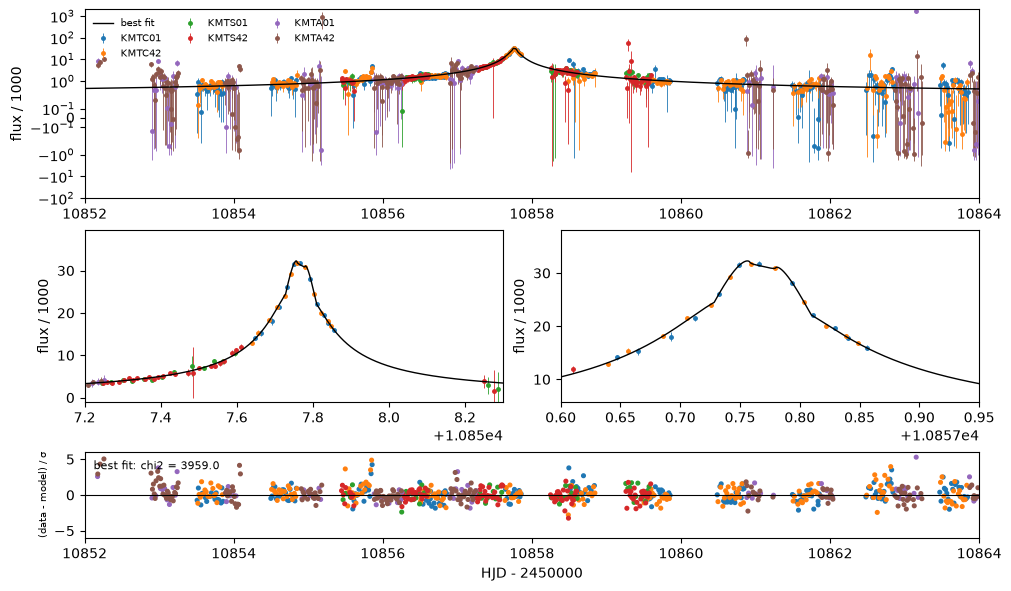

In [4]:
WINDOW, ZOOMS = (10852.0, 10864.0), ((10857.2, 10858.3), (10857.6, 10857.95))


def plot_flux(sols, window=WINDOW, zooms=ZOOMS, d=None):
    # data of all sets on the flux scale of the first set (aligned with the best fit), the first set's model of each
    # solution, two zooms and one panel of normalised residuals per solution (each with its own fluxes); the top
    # panel has a symmetric-log flux axis
    d = data if d is None else d
    styles = ["-", ":", "--", "-.", (0, (5, 1)), (0, (1, 3))]
    fs0, fb0 = lenscape.model.fluxes(lenscape.model.magnification(be, best, d), d)
    fig = plt.figure(figsize=(10, 4.8 + 1.0 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    for ax, (a, b) in zip([top] + zax, [window] + list(zooms)):
        lo, hi = [], []
        tt = np.linspace(a, b, 4000)
        for (name, p), ls in zip(sols.items(), styles):
            fs, fb = lenscape.model.fluxes(lenscape.model.magnification(be, p, d), d)
            mod = (fs[0] * be.lc(lenscape.model.clamp(p)[0], tt) + fb[0]) / 1e3
            ax.plot(tt, mod, linestyle=ls, color="k", lw=1, label=name if ax is top else None, zorder=3)
            lo.append(mod.min()); hi.append(mod.max())
        for k, name in enumerate(d.names):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            f = (d.f[m] - fb0[k]) / fs0[k] * fs0[0] + fb0[0]
            ax.errorbar(d.t[m], f / 1e3, d.e[m] * abs(fs0[0] / fs0[k]) / 1e3, fmt="o", ms=2.5, lw=0.6,
                        color=f"C{k}", label=name if ax is top else None, zorder=2)
        span = max(hi) - min(lo)
        ax.set_xlim(a, b); ax.set_ylabel("flux / 1000")
        if ax is not top:
            ax.set_ylim(min(lo) - 0.15 * span, max(hi) + 0.25 * span)
    top.set_yscale("symlog", linthresh=max(abs(fb0[0] + fs0[0]) / 1e3, 0.1))
    top.legend(fontsize=7, frameon=False, ncol=3, loc="upper left")
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, d)
        m = (d.t > window[0]) & (d.t < window[1])
        ax.scatter(d.t[m], r[m], s=7, c=[f"C{i}" for i in d.idx[m]]); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-6, 6); ax.set_ylabel("(data - model) / σ", fontsize=7)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.1f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel(f"HJD - {2450000}")
    return fig

plot_flux({"best fit": best});

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
or companion at all.

In [5]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], lr], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun
                  for u0 in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3) for lr in (-3.5, -2.5, -1.5))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.1f}")

single-lens floor: Delta chi2 = 47.0


## 3. The paper's map

`data/kb251616_paper_grid.csv` holds the paper's Fig. 2, read from the figure's embedded images at the grid points.
The bands are Δχ² < 80 *k* for *k* = 1…6 (*n* = 80 in the caption); grid points
above 480 are not shown. This map includes the DREAMS data, which our data lack, so its Δχ² scale is not ours.

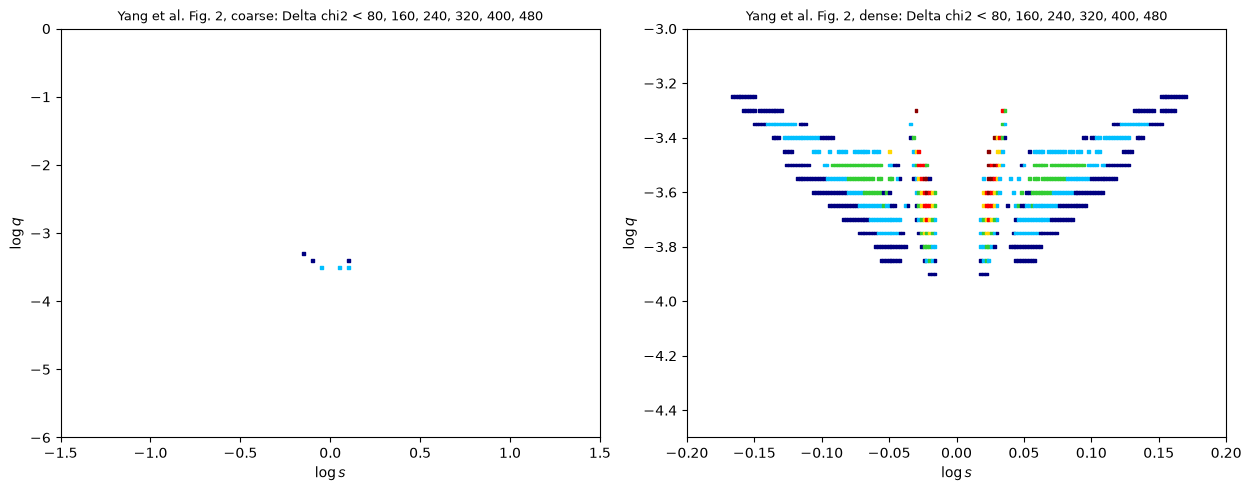

In [6]:
paper = np.genfromtxt("data/kb251616_paper_grid.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                      skip_header=2)
EDGES = np.array([80, 160, 240, 320, 400, 480])                         # the paper's band edges in Delta chi2
band_cmap = ListedColormap(["#8b0000", "red", "gold", "limegreen", "deepskyblue", "navy"] + ["white"])        # the paper's band colours, white above the last band
PANELS = {"coarse": ((-1.5, 1.5), (-6.0, 0.0)), "dense": ((-0.2, 0.2), (-4.5, -3.0))}                                 # paper panel: (log s range, log q range)
fig, axs = plt.subplots(1, len(PANELS), figsize=(6.2 * len(PANELS), 4.8), constrained_layout=True, squeeze=False)
for ax, (panel, (sr, qr)) in zip(axs[0], PANELS.items()):
    sel = paper["panel"] == panel
    ax.scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap, vmin=-0.5,
               vmax=len(EDGES) + 0.5, marker="s", s=4)
    ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
    ax.set_title(f"Yang et al. Fig. 2, {panel}: Delta chi2 < " + ", ".join(f"{e:g}" for e in EDGES), fontsize=9)

## 4. Our 1× maps on the paper's lattices

`lenscape.lattice` with all defaults on the paper's two grids: the coarse 61 × 61 lattice and, independently and also
from scratch, the dense 201 × 31 lattice. Both are stored in `data/`. The dense lattice is computed only once the
coarse map has been inspected (`COMPUTE_DENSE`), since a different region may serve better.

In [7]:
LS_C, LQ_C = np.linspace(-1.5, 1.5, 61), np.linspace(-6.0, 0.0, 61)      # coarse grid of the paper
LS_D, LQ_D = np.linspace(-0.2, 0.2, 201), np.linspace(-4.5, -3.0, 31)    # dense grid of the paper
coarse = run_or_load("coarse_1x", lambda: lenscape.lattice(data, LS_C, LQ_C, best=best, log=log))
OURS = [("coarse 1x", coarse, "coarse")]
COMPUTE_DENSE = False      # the dense lattice waits until the coarse map is inspected (it may move to another region)
if COMPUTE_DENSE or os.path.exists("data/kb251616_map_dense_1x.npz"):
    dense = run_or_load("dense_1x", lambda: lenscape.lattice(data, LS_D, LQ_D, best=best, log=log))
    OURS.append(("dense 1x", dense, "dense"))
for name, m, _ in OURS:
    print(f"{name}: {m['chi2'].shape[0]} x {m['chi2'].shape[1]} points, wall time {m['wall'] / 60:.0f} min")

coarse 1x: 61 x 61 points, wall time 373 min


### Our map next to the paper's

Each of our maps in the paper's bands (same band edges, no rescaling of Δχ²; the reference is the lower of our best
fit and our map minimum), next to the paper's panel of the same region:

coarse 1x: 6 coloured paper points; our band the same at 0 %, within one band at 0 %, above the last band at 0 %


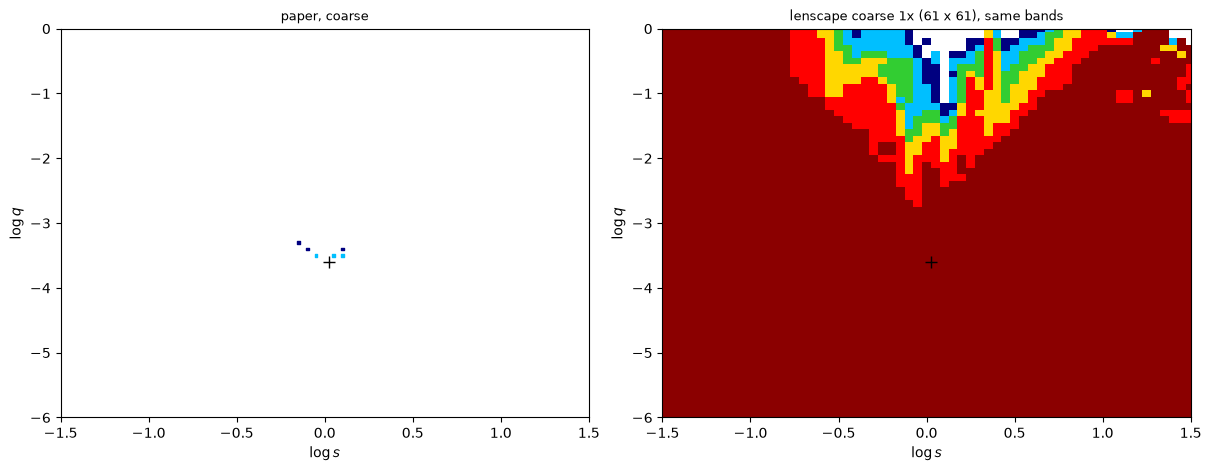

In [8]:
def lowest_ref():
    return min([chi2_best] + [float(np.nanmin(m["chi2"])) for _, m, _ in OURS])

ref = lowest_ref()
fig, axs = plt.subplots(len(OURS), 2, figsize=(12, 4.6 * len(OURS)), constrained_layout=True, squeeze=False)
for row, (name, m, panel) in enumerate(OURS):
    sr, qr = PANELS[panel]
    sel = paper["panel"] == panel
    axs[row, 0].scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap,
                        vmin=-0.5, vmax=len(EDGES) + 0.5, marker="s", s=4)
    axs[row, 0].set_title(f"paper, {panel}", fontsize=9)
    band = np.searchsorted(EDGES, m["chi2"] - ref)
    axs[row, 1].pcolormesh(m["logs"], m["logq"], band.T, cmap=band_cmap, vmin=-0.5, vmax=len(EDGES) + 0.5,
                           shading="nearest")
    axs[row, 1].set_title(f"lenscape {name} ({m['chi2'].shape[0]} x {m['chi2'].shape[1]}), same bands", fontsize=9)
    for ax in axs[row]:
        ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
        ax.plot(best[3], best[4], "k+", ms=9)

# our band at each coloured point of the paper (nearest lattice point inside our map)
for name, m, panel in OURS:
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, m["chi2"][i, j] - ref) + 1
    pb = paper["band"][sel]
    print(f"{name}: {sel.sum()} coloured paper points; our band the same at {100 * np.mean(ours == pb):.0f} %, within "
          f"one band at {100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

### Accuracy of the map values

The maps are computed with lenscape's fast grid backend (relative magnification accuracy about 3 × 10⁻³); the best
fit uses the accurate refine backend. Where many precise points sit at high magnification, the difference can reach a
few χ², which matters for band edges of 4 and 9. Here every map point is evaluated again with the refine backend at
its stored parameters (no refit: an upper bound on the accurate profile χ²), and the band comparison is repeated.
Stored in `data/`; this takes a minute or two.

In [9]:
be_exact = lenscape.make_backend(lenscape.config.REFINE_BACKEND)


def exact_chi2(name, m):
    path = f"data/kb251616_map_{name.replace(' ', '_')}_exact.npy"
    if not RECOMPUTE and os.path.exists(path):
        return np.load(path)
    ex = np.empty_like(m["chi2"])
    for i, ls in enumerate(m["logs"]):
        for j, lq in enumerate(m["logq"]):
            t0, u0, tE, al, lr = m["pars"][i, j]
            ex[i, j] = lenscape.model.chi2(be_exact, np.array([t0, u0, tE, ls, lq, al, lr]), data)
    np.save(path, ex)
    return ex


for name, m, panel in OURS:
    ex = exact_chi2(name, m)
    dd = (ex - m["chi2"])[m["chi2"] - ref < EDGES[-1]]
    print(f"{name}: accurate minus map chi2 where Delta chi2 < {EDGES[-1]:g}: median {np.median(dd):+.2f}, "
          f"5-95 % {np.percentile(dd, 5):+.2f} .. {np.percentile(dd, 95):+.2f}; accurate minimum {ex.min():.2f} "
          f"(map {np.nanmin(m['chi2']):.2f}, best fit {chi2_best:.2f})")
    rex = min(chi2_best, ex.min())
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, ex[i, j] - rex) + 1
    pb = paper["band"][sel]
    print(f"   with accurate values: band the same at {100 * np.mean(ours == pb):.0f} %, within one band at "
          f"{100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

coarse 1x: accurate minus map chi2 where Delta chi2 < 480: median +4.63, 5-95 % -0.02 .. +23.79; accurate minimum 3960.01 (map 3959.95, best fit 3959.00)
   with accurate values: band the same at 0 %, within one band at 0 %, above the last band at 0 %


### Local minima of our map

Lattice points lower than all eight neighbours, with their Δχ² and fitted parameters, next to the published
solutions:

In [10]:
def local_minima(m, max_dchi2):
    c = m["chi2"]; out = []
    for i in range(1, c.shape[0] - 1):
        for j in range(1, c.shape[1] - 1):
            nb = c[i - 1:i + 2, j - 1:j + 2]
            if m.get("folded") and m["logq"][j] > 1e-9:
                continue                                   # folded map: the mirror half repeats the minima
            if c[i, j] <= nb.min() and c[i, j] - ref < max_dchi2:
                out.append((c[i, j] - ref, m["logs"][i], m["logq"][j], m["pars"][i, j]))
    return sorted(out, key=lambda z: z[0])

for name, m, panel in OURS:
    print(f"{name}:")
    for dc, ls, lq, x in local_minima(m, EDGES[-1])[:15]:
        print(f"  Delta chi2 {dc:7.1f}  log s {ls:+.3f}  log q {lq:+.3f}  tE {abs(x[2]):6.1f} d  log rho {x[4]:+.2f}")

coarse 1x:
  Delta chi2     0.9  log s -0.050  log q -3.700  tE   13.6 d  log rho -2.57
  Delta chi2     1.0  log s +0.050  log q -3.700  tE   13.5 d  log rho -2.57
  Delta chi2     7.7  log s -0.700  log q -1.700  tE   23.8 d  log rho -2.69
  Delta chi2     8.0  log s -0.650  log q -1.900  tE   30.6 d  log rho -2.80
  Delta chi2     8.7  log s -0.650  log q -2.500  tE  119.8 d  log rho -3.40
  Delta chi2     8.8  log s -0.650  log q -3.100  tE  477.1 d  log rho -3.99
  Delta chi2     8.8  log s -0.650  log q -3.400  tE  950.2 d  log rho -4.29
  Delta chi2    16.0  log s +0.550  log q -1.800  tE   16.8 d  log rho -2.54
  Delta chi2    17.4  log s +0.600  log q -1.600  tE   12.8 d  log rho -2.42
  Delta chi2    17.9  log s +0.900  log q -1.100  tE   12.8 d  log rho -2.47
  Delta chi2    20.0  log s +0.500  log q -2.100  tE   26.8 d  log rho -2.75
  Delta chi2    21.1  log s +0.900  log q -2.200  tE   21.4 d  log rho -2.45
  Delta chi2    22.4  log s +1.200  log q -1.900  tE   11.0 d  lo

In [11]:
print("published solutions (Table of the paper):")
for name, sol in SOLUTIONS.items():
    print(f"  {name:22s} log s {np.log10(sol[3]):+.3f}  log q {np.log10(sol[4]):+.3f}  tE {sol[2]:6.1f} d")

published solutions (Table of the paper):
  close central          log s -0.079  log q -3.318  tE    8.1 d
  wide central           log s +0.081  log q -3.333  tE    8.1 d
  close resonant         log s -0.025  log q -3.337  tE    8.1 d
  wide resonant          log s +0.029  log q -3.333  tE    8.1 d


## 5. Zoom on the central region

Instead of the paper's dense lattice from scratch (201 × 31 points, about 10 hours at the rate of the coarse map),
we zoom into the same box, log *s* −0.2 … 0.2, log *q* −4.5 … −3.0, by densifying the coarse map: 2×, 4×, 8× and 16×
of its step (0.025 down to 0.003125 dex in log *s*, 0.05 down to 0.00625 dex in log *q*), each from the previous one
(`lenscape.maps.densify`), so every finer map contains the points of the coarser one. The 16× map is eight times
finer than the paper's dense lattice in log *q* and about 1.6 times coarser in log *s*.

In [12]:
def in_box(x0, step, lo, hi):
    # the points x0 + step k of a lattice axis that lie in [lo, hi]
    k = np.arange(int(np.ceil((lo - x0) / step - 1e-9)), int(np.floor((hi - x0) / step + 1e-9)) + 1)
    return x0 + step * k

DLS, DLQ = LS_C[1] - LS_C[0], LQ_C[1] - LQ_C[0]                # steps of the coarse lattice
ZBOX_S, ZBOX_Q = (-0.2, 0.2), (-4.5, -3.0)
FACTORS = (2, 4, 8, 16)
zooms = {1: coarse}
for f in FACTORS:
    prev = zooms[f // 2]
    zooms[f] = run_or_load(f"zoom_{f}x", lambda: lenscape.maps.densify(
        [prev], data, in_box(LS_C[0], DLS / f, *ZBOX_S), in_box(LQ_C[0], DLQ / f, *ZBOX_Q), best=best, log=log))
zref = min(chi2_best, *(float(np.nanmin(m["chi2"])) for m in zooms.values()))
for f in FACTORS:
    m = zooms[f]
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"zoom {f:2d}x: {m['chi2'].shape[0]:3d} x {m['chi2'].shape[1]:3d} points, wall time {m['wall'] / 60:5.1f} min, "
          f"minimum {m['chi2'][i, j] - chi2_best:+7.2f} against the best fit at log s = {m['logs'][i]:+.5f}, "
          f"log q = {m['logq'][j]:.4f}")

zoom  2x:  17 x  31 points, wall time  14.1 min, minimum   +0.08 against the best fit at log s = +0.02500, log q = -3.6000
zoom  4x:  33 x  61 points, wall time  36.7 min, minimum   +0.07 against the best fit at log s = +0.02500, log q = -3.5750
zoom  8x:  65 x 121 points, wall time  65.7 min, minimum   +0.06 against the best fit at log s = +0.02500, log q = -3.5750
zoom 16x: 129 x 241 points, wall time 198.4 min, minimum   +0.06 against the best fit at log s = +0.02500, log q = -3.5750


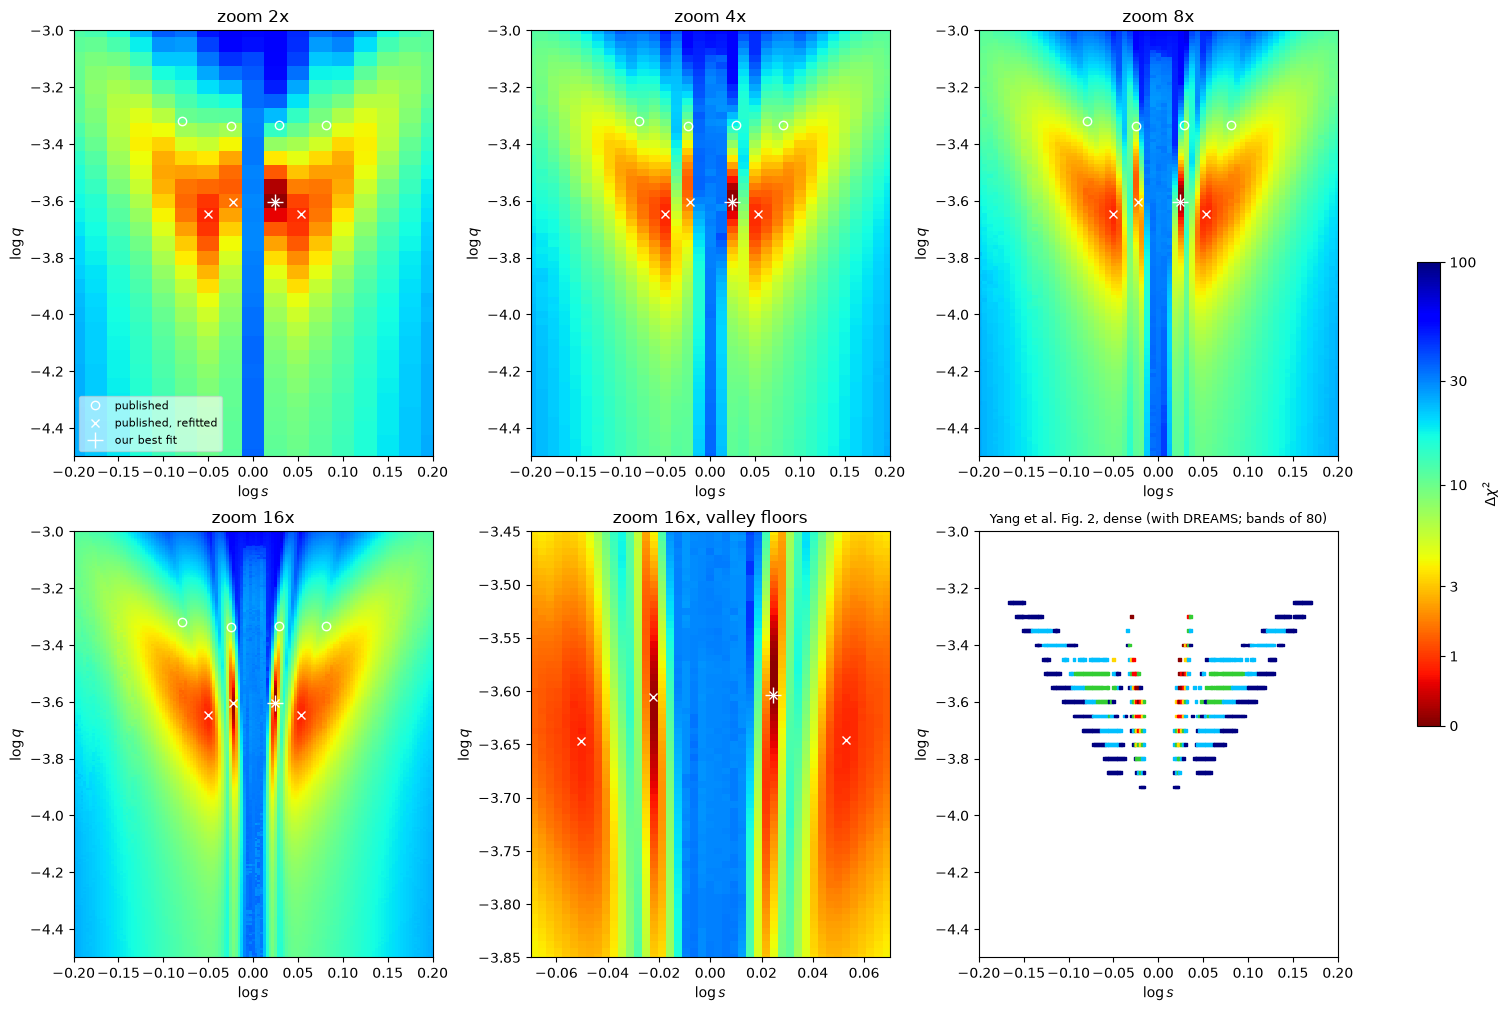

In [13]:
CBOX_S, CBOX_Q = (-0.07, 0.07), (-3.85, -3.45)                 # the four valley floors
fig, axs = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for ax, (f, title) in zip(axs.flat, [(2, "zoom 2x"), (4, "zoom 4x"), (8, "zoom 8x"), (16, "zoom 16x"),
                                     (16, "zoom 16x, valley floors")]):
    figures.plot_map(zooms[f], ax=ax, vmax=100, chi2_ref=zref, colorbar=False)
    for k, sol in enumerate(SOLUTIONS.values()):
        ax.plot(np.log10(sol[3]), np.log10(sol[4]), "wo", mfc="none", ms=6, label="published" if k == 0 else None)
    for k, s in enumerate(bf["solutions"].values()):
        ax.plot(s["p"][3], s["p"][4], "wx", ms=6, label="published, refitted" if k == 0 else None)
    ax.plot(best[3], best[4], "w+", ms=11, label="our best fit")
    box = (CBOX_S, CBOX_Q) if "floors" in title else (ZBOX_S, ZBOX_Q)
    ax.set_xlim(*box[0]); ax.set_ylim(*box[1]); ax.set_title(title)
axs[0, 0].legend(loc="lower left", fontsize=8, framealpha=0.6)
ticks = np.array([0, 1, 3, 10, 30, 100])
cb = fig.colorbar(axs[0, 0].images[0], ax=axs, shrink=0.5, ticks=np.log10(ticks + 1))
cb.set_ticklabels([str(t) for t in ticks]); cb.set_label(r"$\Delta\chi^2$")
ax = axs[1, 2]; sel = paper["panel"] == "dense"
ax.scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap, vmin=-0.5,
           vmax=len(EDGES) + 0.5, marker="s", s=4)
ax.set_xlim(*ZBOX_S); ax.set_ylim(*ZBOX_Q); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
ax.set_title("Yang et al. Fig. 2, dense (with DREAMS; bands of 80)", fontsize=9);

The lowest Δχ² over log *q* at each log *s* (the profile across the valleys), and the lowest point of each valley in
each zoom. The valleys are separated by the ridges at log *s* ≈ −0.031, 0 and +0.034 seen in the 16× profile:

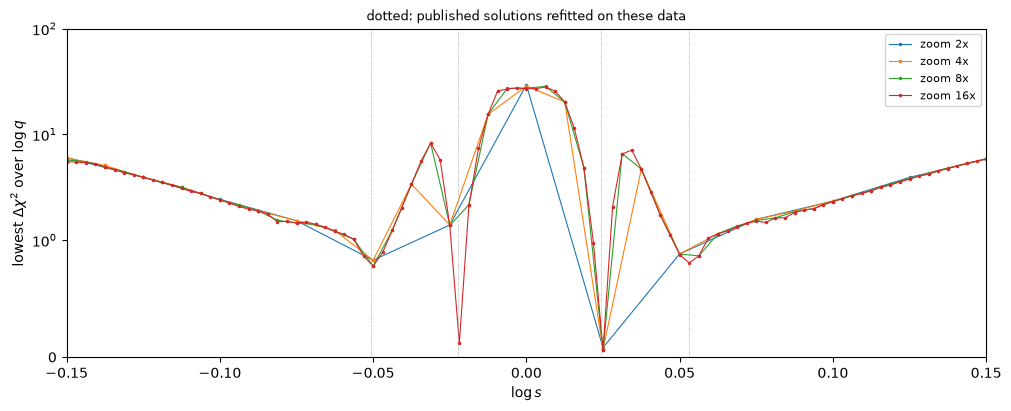

close central (refitted: Delta chi2  0.85 at log s -0.0505, log q -3.647)
   zoom  2x: Delta chi2  0.83 at log s -0.0500, log q -3.650, tE 12.7 d
   zoom  4x: Delta chi2  0.83 at log s -0.0500, log q -3.650, tE 12.7 d
   zoom  8x: Delta chi2  0.78 at log s -0.0500, log q -3.637, tE 12.4 d
   zoom 16x: Delta chi2  0.78 at log s -0.0500, log q -3.637, tE 12.4 d
close resonant (refitted: Delta chi2  0.05 at log s -0.0223, log q -3.605)
   zoom  2x: Delta chi2  1.39 at log s -0.0250, log q -3.550, tE 12.8 d
   zoom  4x: Delta chi2  1.39 at log s -0.0250, log q -3.550, tE 12.8 d
   zoom  8x: Delta chi2  1.38 at log s -0.0250, log q -3.550, tE 12.8 d
   zoom 16x: Delta chi2  0.12 at log s -0.0219, log q -3.612, tE 12.7 d
wide resonant (refitted: Delta chi2  0.00 at log s +0.0244, log q -3.604)
   zoom  2x: Delta chi2  0.08 at log s +0.0250, log q -3.600, tE 13.0 d
   zoom  4x: Delta chi2  0.07 at log s +0.0250, log q -3.575, tE 12.3 d
   zoom  8x: Delta chi2  0.06 at log s +0.0250, log q -3.

In [14]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for f in FACTORS:
    m = zooms[f]
    ax.plot(m["logs"], np.nanmin(m["chi2"], axis=1) - zref, ".-", ms=3, lw=0.8, label=f"zoom {f}x")
for s in bf["solutions"].values():
    ax.axvline(s["p"][3], color="0.6", lw=0.6, ls=":")
ax.set_yscale("symlog", linthresh=1); ax.set_ylim(0, 100); ax.set_xlim(-0.15, 0.15)
ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"lowest $\Delta\chi^2$ over $\log q$"); ax.legend(fontsize=8)
ax.set_title("dotted: published solutions refitted on these data", fontsize=9)
plt.show()

VALLEYS = {"close central": (-0.2, -0.031), "close resonant": (-0.031, 0.0), "wide resonant": (0.0, 0.034),
           "wide central": (0.034, 0.2)}
for name, (lo, hi) in VALLEYS.items():
    s = bf["solutions"][name]
    print(f"{name} (refitted: Delta chi2 {s['chi2'] - zref:5.2f} at log s {s['p'][3]:+.4f}, log q {s['p'][4]:.3f})")
    for f in FACTORS:
        m = zooms[f]; sel = (m["logs"] > lo) & (m["logs"] < hi)
        c = m["chi2"][sel]; i, j = np.unravel_index(np.nanargmin(c), c.shape)
        tE = abs(m["pars"][sel][i, j][2])
        print(f"   zoom {f:2d}x: Delta chi2 {c[i, j] - zref:5.2f} at log s {m['logs'][sel][i]:+.4f}, "
              f"log q {m['logq'][j]:.3f}, tE {tE:4.1f} d")

Convergence at the shared points (every point of a coarser zoom is also a point of the finer one):

In [15]:
def shared(coarse_map, fine):
    # values of the fine map at the points of the coarse one
    i = np.round((coarse_map["logs"] - fine["logs"][0]) / (fine["logs"][1] - fine["logs"][0])).astype(int)
    j = np.round((coarse_map["logq"] - fine["logq"][0]) / (fine["logq"][1] - fine["logq"][0])).astype(int)
    return fine["chi2"][np.ix_(i, j)]

for f in (2, 4, 8):
    c16 = shared(zooms[f], zooms[16]); diff = zooms[f]["chi2"] - c16
    for label, sel in [("Delta chi2 < 20", c16 - zref < 20), ("all", np.isfinite(c16))]:
        print(f"zoom {f}x vs zoom 16x, {label:15s}: {sel.sum():5d} points, coarser higher by > 1 at "
              f"{100 * (diff[sel] > 1).mean():4.1f} %, by > 10 at {100 * (diff[sel] > 10).mean():4.1f} %, "
              f"largest {np.nanmax(diff[sel]):5.1f}")

zoom 2x vs zoom 16x, Delta chi2 < 20:   407 points, coarser higher by > 1 at  0.0 %, by > 10 at  0.0 %, largest   0.7
zoom 2x vs zoom 16x, all            :   527 points, coarser higher by > 1 at  3.6 %, by > 10 at  0.0 %, largest   6.9
zoom 4x vs zoom 16x, Delta chi2 < 20:  1563 points, coarser higher by > 1 at  0.3 %, by > 10 at  0.0 %, largest   1.8
zoom 4x vs zoom 16x, all            :  2013 points, coarser higher by > 1 at  3.1 %, by > 10 at  0.0 %, largest   9.7
zoom 8x vs zoom 16x, Delta chi2 < 20:  6187 points, coarser higher by > 1 at  0.1 %, by > 10 at  0.0 %, largest   1.4
zoom 8x vs zoom 16x, all            :  7865 points, coarser higher by > 1 at  1.6 %, by > 10 at  0.1 %, largest  13.3


**The four solutions.** The zoom shows four valleys, one for each published solution. They lie on both sides of the
s = 1 ridge (Δχ² ≈ 27 at log *s* = 0), all with their floor near log *q* ≈ −3.6 and *t*ₑ ≈ 12.3–12.8 d:

- The two **central** valleys (log *s* ≈ ±0.05) are broad wedges. They reach from log *q* ≈ −3.4 down to −3.9 and
  slant outward toward larger *q* (log *s* ≈ ±0.1 at log *q* = −3.4). Their floors are at Δχ² 0.78 and 0.80.
- The two **resonant** valleys (log *s* ≈ −0.022 and +0.025) are narrow strips next to the s = 1 ridge, and run over
  the same range of log *q*. Low ridges at log *s* ≈ −0.031 and +0.034 (Δχ² ≈ 8 and 7) separate them from the central
  valleys. Their floors are at Δχ² 0.12 and 0.06; the wide resonant floor is the lowest point of all four zooms.

All four floors are within Δχ² 0.8 of each other. These data alone do not separate the solutions, as the paper finds
without DREAMS. Each published solution, refitted on these data (crosses), falls on the floor of its valley. The
refits and the valley floors agree in log *s* to within one 16× step. The published values themselves (circles) lie
at log *q* ≈ −3.33 with *t*ₑ ≈ 8.1 d, above our valleys; these are from KMTNet and PRIME data with limb darkening.

**What the finer zooms changed.** The resonant valleys are narrower than the 2×, 4× and 8× steps in log *s*. The
close resonant floor (log *s* = −0.0219) falls between the points of the coarser lattices. The 2× to 8× maps
therefore show the close resonant valley only at Δχ² 1.4, on its flank at log *s* = −0.025. The 16× map is the
first to hit the floor, at 0.12 (the refit gives 0.05). The wide resonant floor happens to lie at a lattice point
of every zoom (log *s* = +0.025). The central valleys are broad; their floors are found already at 2×.

**Shape compared with the paper.** The paper's dense map (with DREAMS, bands of 80) has the same shape: two outer
wedges slanting outward and two thin inner strips next to log *s* = 0. The scales differ: with DREAMS, the resonant
pair is preferred by Δχ² ≈ 330.

**Convergence.** Where Δχ² < 20, fewer than 0.3 % of the points of the 2×, 4× and 8× maps are higher than the 16× map
by more than 1, and the largest difference is 1.8. Over the whole box, 2–4 % are higher by more than 1. These points
are high on the map, outside the valleys, and the largest difference is 13. Away from the resonant strips, 8× was
already converged. The narrow valleys needed 16×.